In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report,accuracy_score

In [2]:
df = pd.read_csv("Student_Performance.csv")

df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [3]:
df.isnull().value_counts()

Hours Studied  Previous Scores  Extracurricular Activities  Sleep Hours  Sample Question Papers Practiced  Performance Index
False          False            False                       False        False                             False                10000
Name: count, dtype: int64

In [4]:
df["Performance Index"].unique()

array([ 91.,  65.,  45.,  36.,  66.,  61.,  63.,  42.,  69.,  84.,  73.,
        27.,  33.,  68.,  43.,  67.,  70.,  30.,  71.,  85.,  57.,  35.,
        49.,  83.,  74.,  39.,  58.,  47.,  60.,  32.,  64.,  54.,  17.,
        53.,  75.,  52.,  78.,  38.,  98.,  87.,  41.,  81.,  15.,  88.,
        95.,  29.,  21.,  76.,  25.,  34.,  50.,  56.,  82.,  23.,  46.,
        92.,  77.,  86.,  44.,  94.,  40., 100.,  31.,  26.,  18.,  51.,
        72.,  16.,  28.,  89.,  48.,  37.,  62.,  59.,  19.,  79.,  22.,
        10.,  90.,  80.,  24.,  20.,  96.,  55.,  97.,  12.,  93.,  14.,
        99.,  11.,  13.])

In [5]:
df.rename(columns={'Sample Question Papers Practiced': 'Papers_Practiced'}, inplace=True)
print("Shape: ", df.shape)
print("\nValue Counts", df["Extracurricular Activities"].value_counts())

Shape:  (10000, 6)

Value Counts Extracurricular Activities
No     5052
Yes    4948
Name: count, dtype: int64


/tmp/ipykernel_1106692/2266750825.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'Sample Question Papers Practiced': 'Papers_Practiced'}, inplace=True)


In [6]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Papers_Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


Text(0.5, 1.0, 'Correlaction Between Variables')

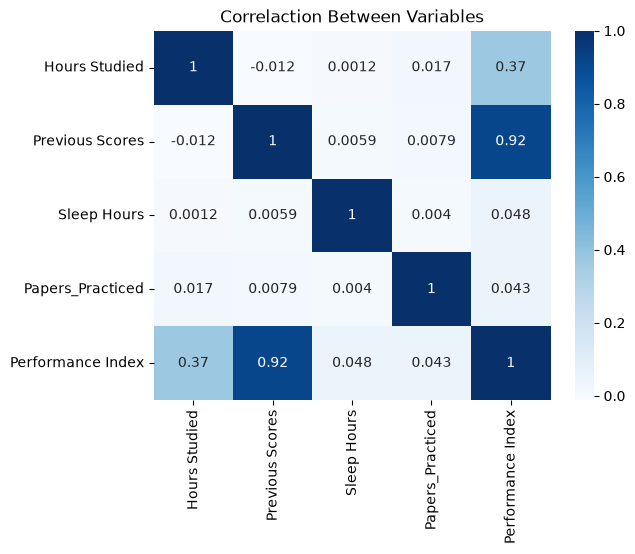

In [7]:
sns.heatmap(df.drop(columns=["Extracurricular Activities"]).corr(), annot=True, cmap='Blues')
plt.title("Correlaction Between Variables")

Text(0.5, 1.0, 'Relationship Between Previous Scores & Performance')

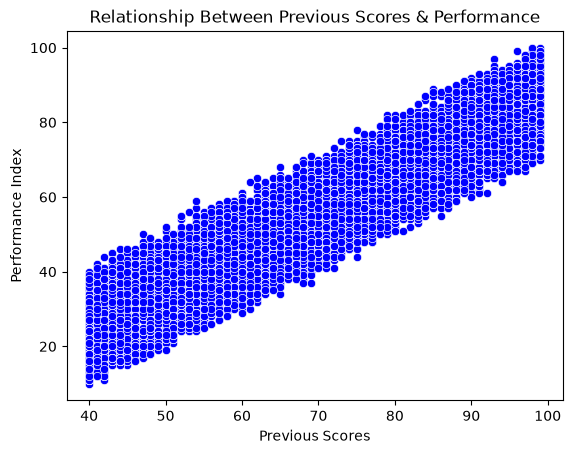

In [8]:
sns.scatterplot(x=df["Previous Scores"], y=df["Performance Index"], color="blue")
plt.title("Relationship Between Previous Scores & Performance")

/tmp/ipykernel_1106692/3929900531.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Sleep Hours", palette="coolwarm")


Text(0.5, 1.0, 'Distribution of Hours Slept')

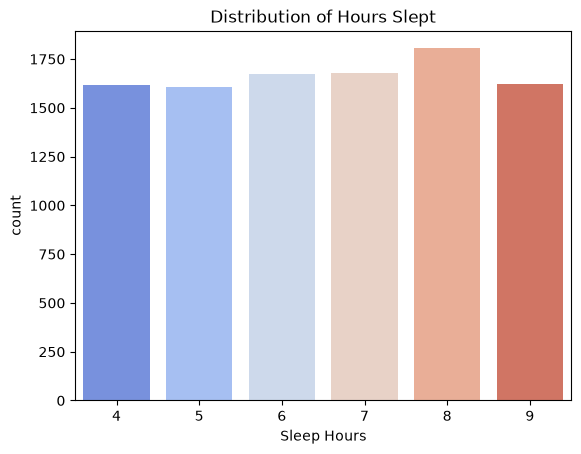

In [9]:
sns.countplot(data=df, x="Sleep Hours", palette="coolwarm")
plt.title("Distribution of Hours Slept")

In [10]:
df["Extracurricular Activities"] = df["Extracurricular Activities"].replace(["Yes", "No"], [1, 0])

df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Papers_Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [11]:
df.dtypes

Hours Studied                   int64
Previous Scores                 int64
Extracurricular Activities     object
Sleep Hours                     int64
Papers_Practiced                int64
Performance Index             float64
dtype: object

In [12]:
X = df[["Hours Studied", "Previous Scores", "Extracurricular Activities", "Sleep Hours", "Papers_Practiced"]]
Y = df[["Performance Index"]]

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=10)

In [13]:
lg = LinearRegression()
lg.fit(x_train, y_train)

y_pred = lg.predict(x_test)

In [14]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Mean Square Errors: ", mse)
print("Root Mean Square Errors: ", rmse)

Mean Square Errors:  4.192884822397506
Root Mean Square Errors:  2.0476534917796774


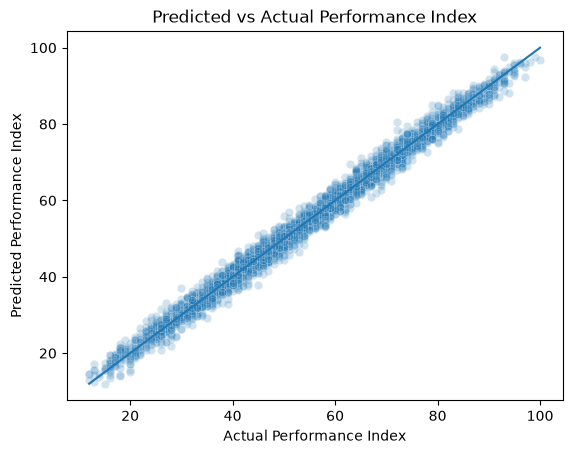

In [15]:
y_test = np.ravel(y_test)
y_pred = np.ravel(y_pred)

plt.figure()
sns.scatterplot(x=y_test, y=y_pred, alpha=0.2)
plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("Predicted vs Actual Performance Index")

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims)
plt.show()

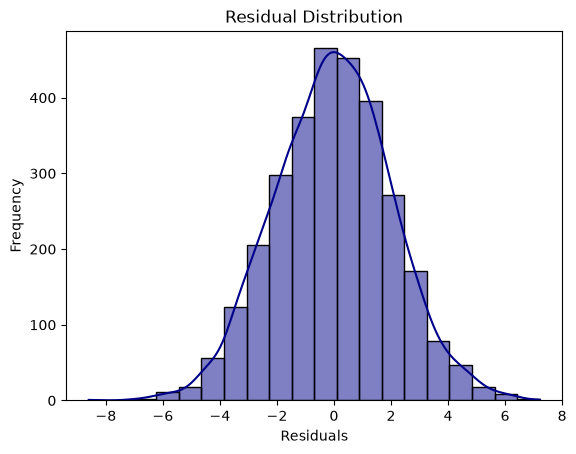

In [16]:
residuals = y_test - y_pred

sns.histplot(residuals, kde=True, color='darkblue', bins=20)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.show()

In [17]:
df = pd.read_csv("weather_classification_data.csv")

df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy


In [18]:
df.isnull().value_counts()

Temperature  Humidity  Wind Speed  Precipitation (%)  Cloud Cover  Atmospheric Pressure  UV Index  Season  Visibility (km)  Location  Weather Type
False        False     False       False              False        False                 False     False   False            False     False           13200
Name: count, dtype: int64

In [19]:
print("Shape: ", df.shape)
df["Weather Type"].value_counts()

Shape:  (13200, 11)


Weather Type
Rainy     3300
Cloudy    3300
Sunny     3300
Snowy     3300
Name: count, dtype: int64

In [20]:
df["Cloud Cover"].value_counts()

Cloud Cover
overcast         6090
partly cloudy    4560
clear            2139
cloudy            411
Name: count, dtype: int64

In [21]:
df["Season"].value_counts()

Season
Winter    5610
Spring    2598
Autumn    2500
Summer    2492
Name: count, dtype: int64

In [22]:
df["Location"].value_counts()

Location
inland      4816
mountain    4813
coastal     3571
Name: count, dtype: int64

In [23]:
df.dtypes

Temperature             float64
Humidity                  int64
Wind Speed              float64
Precipitation (%)       float64
Cloud Cover                 str
Atmospheric Pressure    float64
UV Index                  int64
Season                      str
Visibility (km)         float64
Location                    str
Weather Type                str
dtype: object

In [24]:
df.describe()

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
count,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000
mean,19.127576,68.710833,9.832197,53.644394,1005.827896,4.005758,5.462917
std,17.386327,20.194248,6.908704,31.946541,37.199589,3.856600,3.371499
min,-25.000000,20.000000,0.000000,0.000000,800.120000,0.000000,0.000000
25%,4.000000,57.000000,5.000000,19.000000,994.800000,1.000000,3.000000
50%,21.000000,70.000000,9.000000,58.000000,1007.650000,3.000000,5.000000
75%,31.000000,84.000000,13.500000,82.000000,1016.772500,7.000000,7.500000
max,109.000000,109.000000,48.500000,109.000000,1199.210000,14.000000,20.000000


Text(0.5, 1.0, 'Correlaction Between Variables')

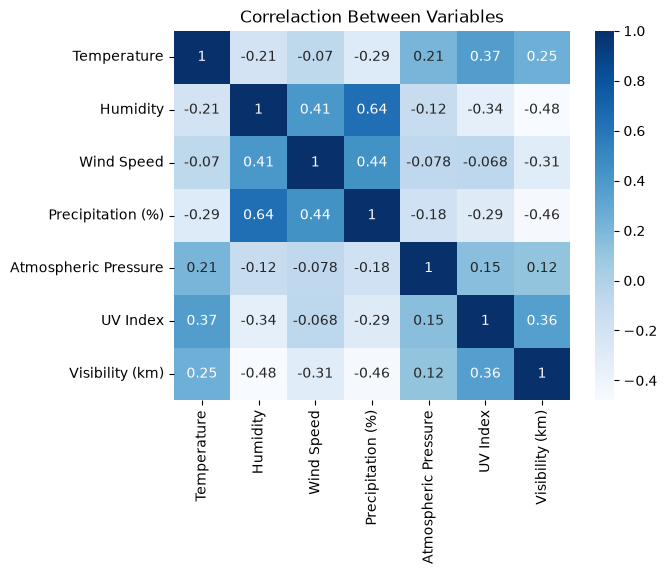

In [25]:
sns.heatmap(df.drop(columns=["Weather Type", "Cloud Cover", "Season", "Location"]).corr(),
            annot=True, cmap='Blues')

plt.title("Correlaction Between Variables")

/tmp/ipykernel_1106692/472955236.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df['Temperature'], shade=True)


Text(0.5, 1.0, 'Distribution of Temperature in Fahrenheit')

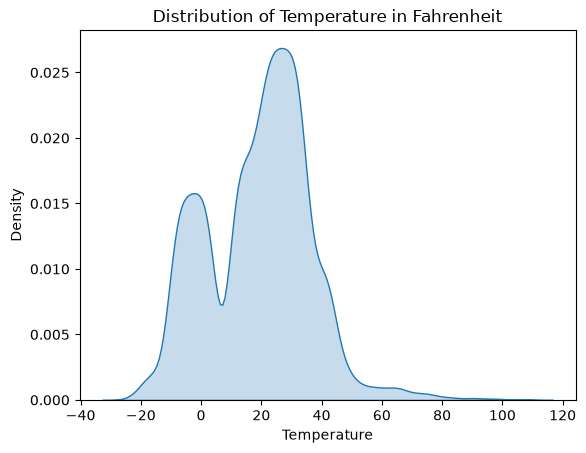

In [26]:
sns.kdeplot(df['Temperature'], shade=True)
plt.title("Distribution of Temperature in Fahrenheit")

/tmp/ipykernel_1106692/2174095819.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Weather Type', y='Temperature', data=mean_temp, palette='coolwarm')


Text(0.5, 1.0, 'Average Temperature by Weather Type')

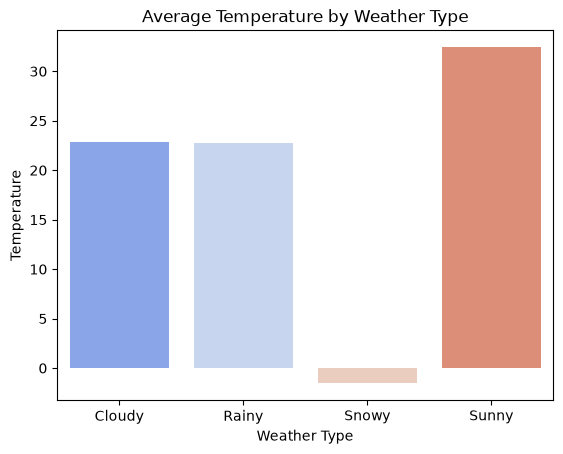

In [27]:
mean_temp = df.groupby('Weather Type')['Temperature'].mean().reset_index()

sns.barplot(x='Weather Type', y='Temperature', data=mean_temp, palette='coolwarm')
plt.title('Average Temperature by Weather Type')

/tmp/ipykernel_1106692/3622326971.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Season', y='Temperature', data=df, palette='Set2')


Text(0.5, 1.0, 'Temperature Distribution Across Seasons')

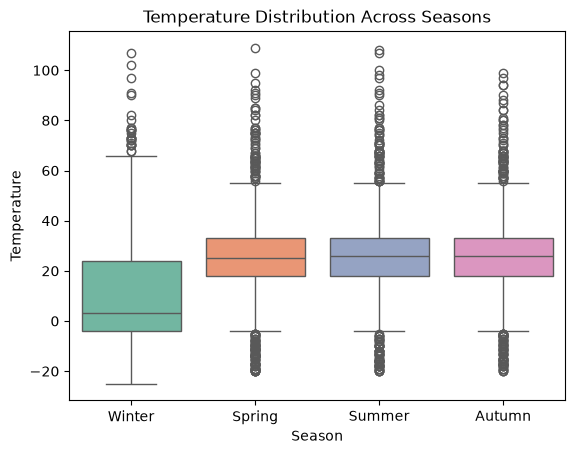

In [28]:
sns.boxplot(x='Season', y='Temperature', data=df, palette='Set2')
plt.title('Temperature Distribution Across Seasons')

In [29]:
le = LabelEncoder()
df["Weather Type"] = le.fit_transform(df["Weather Type"])
df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,1
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,0
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,3
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,3
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,1


In [30]:
df["Cloud Cover"] = df["Cloud Cover"].replace(["clear", "partly cloudy", "cloudy", "overcast"], [0, 1, 2, 3])
df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,1,1010.82,2,Winter,3.5,inland,1
1,39.0,96,8.5,71.0,1,1011.43,7,Spring,10.0,inland,0
2,30.0,64,7.0,16.0,0,1018.72,5,Spring,5.5,mountain,3
3,38.0,83,1.5,82.0,0,1026.25,7,Spring,1.0,coastal,3
4,27.0,74,17.0,66.0,3,990.67,1,Winter,2.5,mountain,1


In [31]:
df = pd.get_dummies(df, columns=["Location", "Season"], drop_first=True, dtype="int")
df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Visibility (km),Weather Type,Location_inland,Location_mountain,Season_Spring,Season_Summer,Season_Winter
0,14.0,73,9.5,82.0,1,1010.82,2,3.5,1,1,0,0,0,1
1,39.0,96,8.5,71.0,1,1011.43,7,10.0,0,1,0,1,0,0
2,30.0,64,7.0,16.0,0,1018.72,5,5.5,3,0,1,1,0,0
3,38.0,83,1.5,82.0,0,1026.25,7,1.0,3,0,0,1,0,0
4,27.0,74,17.0,66.0,3,990.67,1,2.5,1,0,1,0,0,1


In [32]:
X = df.drop(columns=["Weather Type"])
Y = df[["Weather Type"]]

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=10)

lr = LogisticRegression(max_iter=1000, multi_class="auto")
lr.fit(x_train, y_train)

y_pred = lr.predict(x_test)

TypeError: LogisticRegression.__init__() got an unexpected keyword argument 'multi_class'

In [ ]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy on test set: {acc:.4f}")

In [ ]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

In [ ]:
plt.figure()
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_,
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix - Logistic Regression on Weather Types")
plt.show()